In [1]:
import mc_astra as mca
import scanpy as sc
import scanpy.external as sce
import numpy as np
import decoupler as dc
import math
import mofaflex as mf
import mudata as md
import pandas as pd
import matplotlib.pyplot as plt
import squidpy as sq

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# packages for font managing
from pathlib import Path
import matplotlib as mpl
from matplotlib import font_manager

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Versio

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



In [2]:
def font_aesthetics():

    FONT_DIR = Path("fonts/liberation_sans")

    font_files = [
        "LiberationSans-Regular.ttf",
        "LiberationSans-Italic.ttf",
        "LiberationSans-Bold.ttf",
        "LiberationSans-BoldItalic.ttf",
    ]

    for filename in font_files:
        font_path = FONT_DIR / filename

        if not font_path.exists():
            raise FileNotFoundError(f"Font file not found: {font_path.resolve()}")

        font_manager.fontManager.addfont(font_path)

    # Read the font's internal family name rather than assuming it
    regular_font = FONT_DIR / "LiberationSans-Regular.ttf"
    font_name = font_manager.FontProperties(fname=regular_font).get_name()

    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [font_name, "DejaVu Sans"],

        # Preserve editable TrueType text in PDF and PostScript output
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    sc.set_figure_params(
    dpi=120,
    dpi_save=400,
    fontsize=10,
    facecolor="white",
)

    FONT_DIR = Path("fonts/liberation_sans")

    for font_path in FONT_DIR.glob("*.ttf"):
        font_manager.fontManager.addfont(font_path)

    font_name = font_manager.FontProperties(
        fname=FONT_DIR / "LiberationSans-Regular.ttf"
    ).get_name()

    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [font_name, "DejaVu Sans"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

#### MAIN

/tmp/ipykernel_2122907/3640572737.py:2: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
/tmp/ipykernel_2122907/3640572737.py:3: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/pl/_spatial_ut

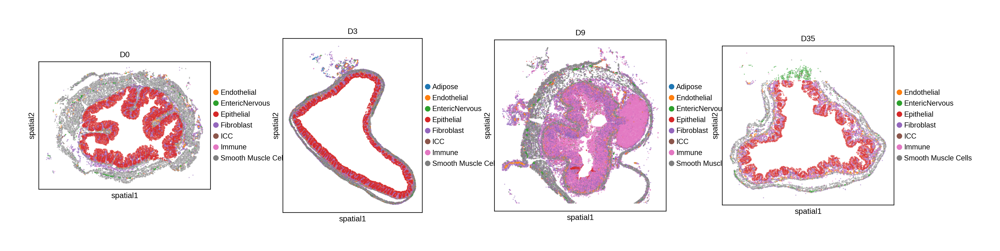

In [3]:
font_aesthetics()
adata = sc.read_h5ad("/nfs/research/saezrodriguez/data/ERC_CartoHostBug/MERFISH/full_adata.h5ad")
adata = adata[adata.obs["Sample_type"] != "DSS21"].copy()

# Take out "DSS" and make Healthy 0 from Sample_type
adata.obs["time"] = adata.obs["Sample_type"].apply(lambda x: 0 if x == "Healthy" else x.replace("DSS", ""))
adata.obs["time"] = adata.obs["time"].astype(str).astype(int)

# add obs names
adata.obs_names = adata.obs["Cell_ID"].to_list()

cats = sorted(adata.obs["TierMINA"].dropna().unique())
# Force all slices to use the same categories, even if some are absent
adata.obs["TierMINA"] = pd.Categorical(
    adata.obs["TierMINA"],
    categories=cats,
    ordered=False,
)

sq.pl.spatial_scatter(
    adata,
    library_key= "Slice_ID",
    library_id = ["062921_D0_m3a_2_slice_2", "092421_D3_m4_1_slice_3", 
                  "062921_D9_m5_1_slice_1", "072523_D35_m11_1_slice_1"],
    shape=None,
    color=[
        "Tier1"
    ],
    ncols=4,
    title = ["D0", "D3", "D9", "D35"],
)

In [4]:
# We extract the metadata based on our column that is the reference
# Filter adata to only include ileum
# Process adata_raw
metadata = mca.up.extract_metadata_from_obs(obs=adata.obs, groupby="Slice_ID", sort=False)

#Define order of time points
metadata["Sample_type"] = pd.Categorical(metadata["Sample_type"], categories=["Healthy", "DSS3", "DSS9", "DSS21", "DSS35"], ordered=True)

pdata = dc.pp.pseudobulk(adata, sample_col="Slice_ID", groups_col="Tier1")

contaminants_dict = mca.up.get_contaminant_genes(pdata,
                      view_group="Tier1",
                      min_count=5,
                      min_total_count=10,
                      large_n=10,
                      min_prop=0.4,
                      lfc_threshold=1.5,
                      p_threshold=0.05)

# Manipulations on pdata
pdata.obs = pdata.obs.set_index("Slice_ID", drop=False)
pdata.obs.index.name = None

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoup

In [5]:
# Make list of adatas per pseudobulk cell type
anndata_dict = mca.up.split_anndata_by_celltype(pdata=pdata, grouping="Tier1")

# Adding gene expression total counts - TODO add to upstream as a function
for _cell_type, adata_raw in anndata_dict.items():
    # Sum across observations (rows) for each gene (column)
    if hasattr(adata_raw.X, "toarray"):
        # Sparse matrix case
        total_counts = adata_raw.X.sum(axis=0).A1  # returns 1D array
    else:
        total_counts = adata_raw.X.sum(axis=0)  # numpy array

    # Add to .var
    adata_raw.var["total_counts"] = total_counts

### Molecular views

In [6]:
mca.up.filt.filter_anndata_by_ncells(anndata_dict, min_cells=10)
# From all the possible samples, let's ask for at least 40%
n_samples = len(metadata.index)
min_samples =  math.trunc((n_samples * 0.9))
mca.up.filter_views_by_samples(anndata_dict, min_rows=min_samples)
mca.up.filter_genes_byexpr(anndata_dict, min_count=5, min_prop=0.4)
mca.up.filter_views_by_genes(anndata_dict, min_genes_per_view=50)
mca.up.filter_samples_by_coverage(anndata_dict, threshold=0, min_prop=0.95)
mca.up.filter_views_by_samples(anndata_dict, min_rows=min_samples)
mca.up.save_raw_counts(anndata_dict, layer_name="raw_counts")
mca.up.norm_log(anndata_dict, target_sum=1e5, exclude_highly_expressed=False, max_value=None, center=True)
contaminants_dict = {ct:values for ct, values in contaminants_dict.items() if ct in anndata_dict.keys()}
mca.up.filter_genes_by_celltype(anndata_dict, contaminants_dict)
mca.up.utils.append_view_to_var(anndata_dict)

Raw counts saved in the 'raw_counts' layer for each AnnData object.
Normalization, log-transformation, and scaling complete for all AnnData objects with target_sum = 100000.0.


In [7]:
anndata_dict

{'Endothelial': AnnData object with n_obs × n_vars = 54 × 506
     obs: 'Slice_ID', 'Tier1', 'Mouse_ID', 'Technical_repeat_number', 'Sample_type', 'dataset', 'time', 'psbulk_cells', 'psbulk_counts'
     var: 'total_counts', 'mean', 'std'
     uns: 'log1p'
     layers: 'psbulk_props', None (.X), 'raw_counts',
 'EntericNervous': AnnData object with n_obs × n_vars = 53 × 479
     obs: 'Slice_ID', 'Tier1', 'Mouse_ID', 'Technical_repeat_number', 'Sample_type', 'dataset', 'time', 'psbulk_cells', 'psbulk_counts'
     var: 'total_counts', 'mean', 'std'
     uns: 'log1p'
     layers: 'psbulk_props', None (.X), 'raw_counts',
 'Epithelial': AnnData object with n_obs × n_vars = 54 × 595
     obs: 'Slice_ID', 'Tier1', 'Mouse_ID', 'Technical_repeat_number', 'Sample_type', 'dataset', 'time', 'psbulk_cells', 'psbulk_counts'
     var: 'total_counts', 'mean', 'std'
     uns: 'log1p'
     layers: 'psbulk_props', None (.X), 'raw_counts',
 'Fibroblast': AnnData object with n_obs × n_vars = 54 × 504
     ob

### Compositional view

In [8]:
clr_props_adata = mca.up.get_cell_props(adata, "Slice_ID", "TierMINA", metadata)
mca.up.utils.append_view_to_var({"clr_comps":clr_props_adata})
anndata_dict["clr_comps"] = clr_props_adata

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/up/utils.py:497: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    ['062221_D9_m3_2_slice_1', '062221_D9_m3_2_slice_2', '062221_D9_m3_2_slice_3', '062921_D0_m3a_1_slice_1', '062921_D0_m3a_1_slice_2']

    Inferred to be: categorical



### Spatial view

In [9]:
spatial_interaction_adata = mca.up.get_nhood_enrichment_feats(
    adata,
    sample_key="Slice_ID",
    cluster_key="TierMINA",
    diagonal = True, # To co
    n_perms=1000,
    metadata=metadata
)

# Don't forget to add the view name to the variables for compatibility
mca.up.utils.append_view_to_var({"Spatial":spatial_interaction_adata})
anndata_dict["spatial"] = spatial_interaction_adata

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:02<00:00, 405.56/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:02<00:00, 405.06/s]


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:02<00:00, 466.11/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


... (98 outputs left out)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:01<00:00, 513.53/s]


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:01<00:00, 554.84/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


### MEFISTOcell
Using the SpikeSlab prior but time gaussian processes

In [10]:
for cell_type, ad in anndata_dict.items():
    # Add the time in .obs to .obsm as numpy.ndarray
    ad.obsm["time"] = ad.obs["time"].to_numpy().reshape(-1, 1)

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/anndata/_core/views.py:154: RuntimeWarning: invalid value encountered in subtract


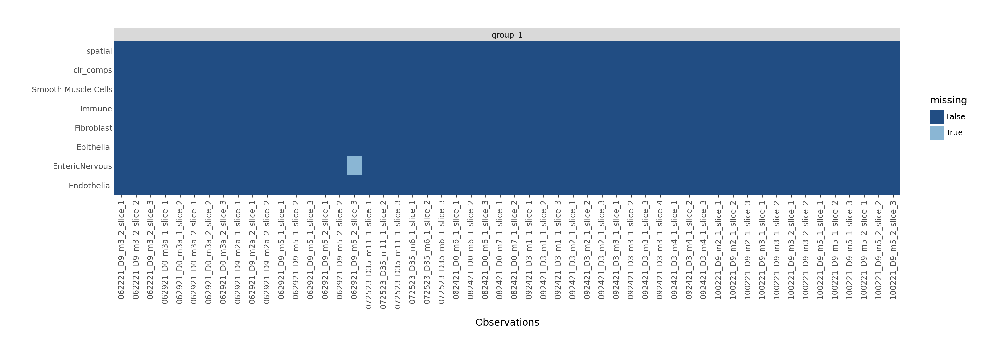

INFO	Initializing factors using 'pca' method...
100%|██████████| 10000/10000 [39:35<00:00,  4.21epoch/s, Loss=4.8e+3] 
INFO	Saving results to mofaflex_20260731_164157.h5...


In [11]:
mdata = md.MuData(anndata_dict)

# Fitting model
model_time = mf.terms.MofaFlex(
    n_factors=10,
    weight_prior="Horseshoe",
    factor_prior=mf.priors.GaussianProcess(
        covariates_mkey="time", 
        n_inducing=100, 
        kernel="RBF"
    ),
    nonnegative_weights=False,
    nonnegative_factors=False,
    init_factors="pca"
)

model_time.fit(
    mdata,
    likelihoods=mf.likelihoods.Normal(scale_per_group=True),
    early_stopper_patience=2000,
    lr=0.001,
)

In [12]:
amodel_full = mca.down.model_to_anndata(
    anndata_dict=anndata_dict,
    metadata=metadata,
    model=model_time,
)

amodel_full.obs["Sample_type"] = pd.Categorical(amodel_full.obs["Sample_type"], 
                                           categories = ["Healthy", "DSS3", "DSS9", "DSS35"],
                                           ordered=True)

In [ ]:
# Save model
# amodel_full.write_h5ad("./results/MERFISH/full_model_MEFISTO.h5ad")

In [11]:
amodel_full = sc.read_h5ad("./results/MERFISH/full_model_MEFISTO.h5ad")

In [12]:
# Count how many samples per group in obs
amodel_full.obs.groupby("Sample_type").size()

Sample_type
Healthy    10
DSS3       13
DSS9       25
DSS35       6
dtype: int64

In [13]:
# Clean the var names of each view by taking their "view:" prefix 
anndata_dict_cleaned = {}

for view_name, ad in anndata_dict.items():
    # Remove the "view:" prefix from the variable names
    adata_cleaned = ad.copy()
    adata_cleaned.var_names = [var_name.replace(f"{view_name}:", "") for var_name in ad.var_names]
    adata_cleaned.obs["Sample_type"] = pd.Categorical(adata_cleaned.obs["Sample_type"], 
                                           categories = ["Healthy", "DSS3", "DSS9", "DSS35"],
                                           ordered=True)

    # Store the cleaned AnnData object in the new dictionary
    anndata_dict_cleaned[view_name] = adata_cleaned


In [14]:
mca.down.get_associations(amodel_full, 
                           test_variable = "Sample_type",
                           test_type="categorical",
                           random_effect = None)

,feature,statistic,p_value,adj_p_value
0,Factor1,37.093952,9.238294e-13,9.238294e-12
1,Factor2,7.712274,2.487962e-04,4.975924e-04
2,Factor3,16.206530,1.729025e-07,5.763416e-07
3,Factor4,13.361900,1.584703e-06,3.961758e-06
4,Factor5,4.086440,1.134810e-02,1.418512e-02
5,Factor6,4.309419,8.843999e-03,1.263428e-02
6,Factor7,1.485346,2.298227e-01,2.298227e-01
7,Factor8,2.505157,6.969456e-02,7.743840e-02
8,Factor9,4.938431,4.421520e-03,7.369199e-03
9,Factor10,17.832525,5.286417e-08,2.643209e-07


In [19]:
mpl.rcdefaults()

FONT_DIR = Path("fonts/liberation_sans")

font_files = [
    "LiberationSans-Regular.ttf",
    "LiberationSans-Italic.ttf",
    "LiberationSans-Bold.ttf",
    "LiberationSans-BoldItalic.ttf",
]

for filename in font_files:
    font_path = FONT_DIR / filename

    if not font_path.exists():
        raise FileNotFoundError(
            f"Font file not found: {font_path.resolve()}"
        )

    font_manager.fontManager.addfont(font_path)

regular_font = FONT_DIR / "LiberationSans-Regular.ttf"
font_name = font_manager.FontProperties(
    fname=regular_font
).get_name()

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [font_name, "DejaVu Sans"],

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # Explicitly restore layout-related defaults
    "legend.loc": "best",
    "figure.autolayout": False,
    "figure.constrained_layout.use": False,
})




In [20]:
# Using a explicit dictionary of colors for each group
custom_palette_dict = {'Healthy': "#00cdcd", 'DSS3': 'orange', 'DSS9': 'red', 'DSS35': 'dodgerblue'}
custom_palette = ["#00cdcd", "orange", "red", "dodgerblue"]
sc.pl.violin(amodel_full,
             amodel_full.var_names.to_list(), 
             groupby="Sample_type", rotation=90,size = 3, palette=custom_palette_dict)

### Selecting factors for next steps
"Factor1" and "Factor2" require to flip both, loadings and factor scores for interpretability

In [16]:
# Multiply column index [0,1] of .X by -1
amodel_full.X[:, [0, 1]] *= -1
amodel_full.varm['gene_loadings'][[0, 1], :] *= -1

/tmp/ipykernel_2122907/3904358185.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


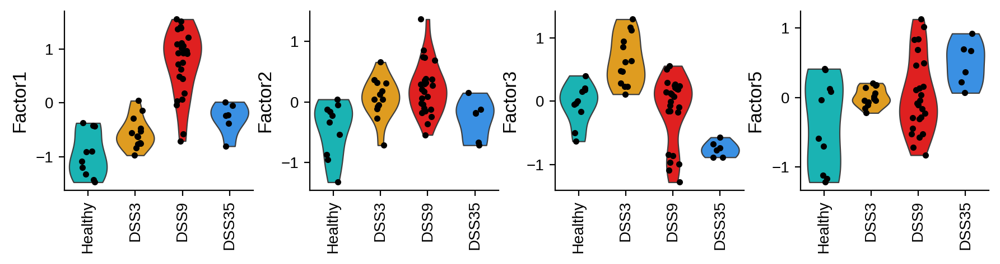

In [21]:
sc.pl.violin(amodel_full,
             ["Factor1", "Factor2","Factor3", "Factor5"], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            show=False,
            palette=custom_palette_dict
        )

fig = plt.gcf()
fig.set_size_inches(10, 2.2)

for ax in fig.axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=10)  # tick labels
    ax.xaxis.label.set_size(12)                # x-axis label
    ax.yaxis.label.set_size(12)                # y-axis label

    ax.tick_params(axis="x", pad=3)
    ax.yaxis.set_label_coords(-0.19, 0.5)

fig.tight_layout()

# Then explicitly increase horizontal gap between panels
fig.subplots_adjust(wspace=0.45)


plt.savefig("./results/Figures/Figure3/violin_factors_Sample_type.pdf",
            bbox_inches="tight",
            pad_inches=0.08)
plt.show()
plt.close(fig)  # Explicitly finish this figure

/tmp/ipykernel_2122907/3756908251.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


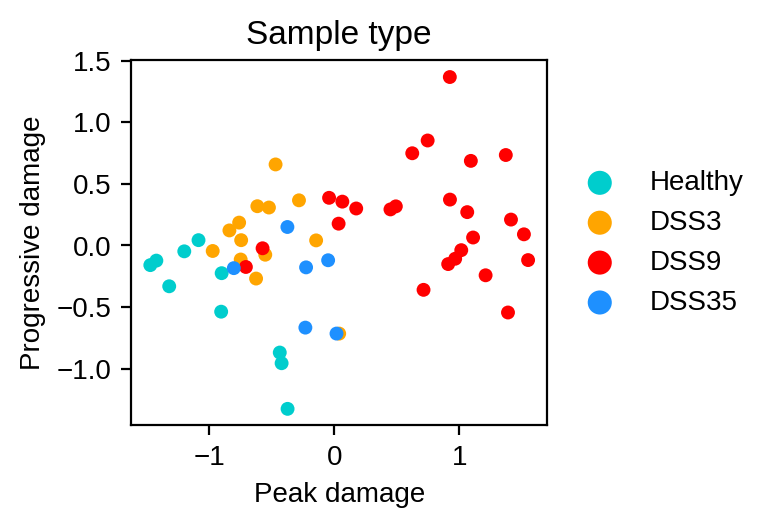

In [22]:
sc.pl.scatter(amodel_full,
              x = "Factor1",
              y = "Factor2", 
              color  = "Sample_type", 
              size =100,
              show=False,
              palette=custom_palette)

fig = plt.gcf()
fig.set_size_inches(3.5, 2.5)

ax = fig.gca()
ax.grid(False)

# Change the x and y labels
ax.set_xlabel("Peak damage")
ax.set_ylabel("Progressive damage")

fig.tight_layout()

# Then explicitly increase horizontal gap between panels
fig.subplots_adjust(wspace=0.45)

plt.savefig("./results/Figures/Figure3/scatter_recovery.pdf",
            bbox_inches="tight",
            pad_inches=0.08)
plt.show()
plt.close(fig)  # Explicitly finish this figure

### Relative proportion of explained variance

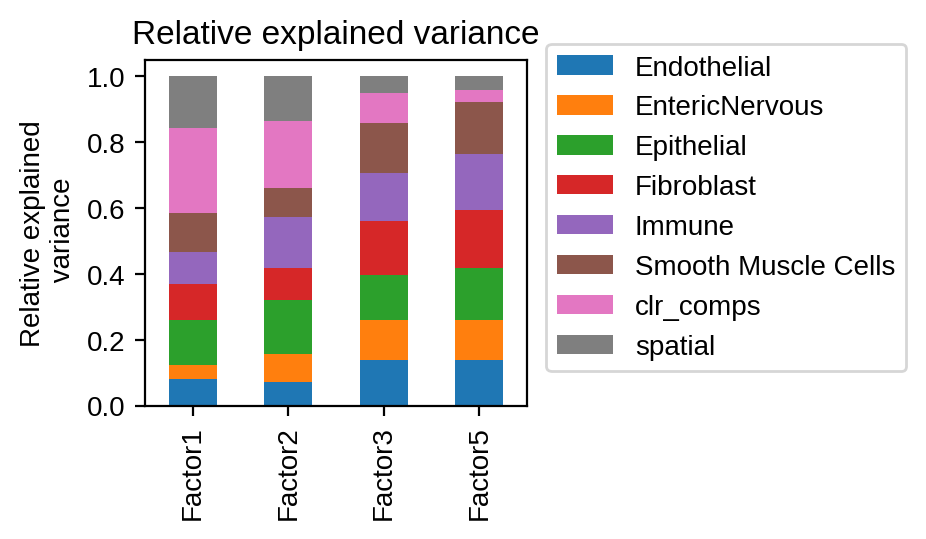

In [23]:
var_summ = amodel_full.var.iloc[[0,1,2,4],:].copy()
# Delete suffix ":group_1" from colums
var_summ.columns = var_summ.columns.str.replace(":group_1", "", regex=False)

# Make each row value, a relative value to the sum of the row
var_summ =  var_summ.div(var_summ.sum(axis=1), axis=0)

# Make the index a colum
var_summ.reset_index(inplace=True)


var_summ.plot(x='index',
        kind='bar',
        stacked=True,
        title='Relative explained variance')

fig = plt.gcf()
ax = fig.gca()
fig.set_size_inches(2.5, 3)
fig.tight_layout(w_pad=2)
plt.xlabel("")
ax.grid(False)
plt.ylabel("Relative explained\n variance")
plt.legend(loc=(1.05, 0.1))
plt.savefig("./results/Figures/Figure3/relative_explained_variance.pdf")
plt.show()
plt.close(fig)  # Explicitly finish this figure

In [24]:
amodel_full.var.iloc[[0,1,2,4],:].mean(axis=1)

Factor1    0.244386
Factor2    0.054598
Factor3    0.094071
Factor5    0.066230
dtype: float64

In [25]:
# Characterizing Factor Loadings
# First we need to make the gene loadings a pandas DataFrame with named columns and indexes
# Wrap as DataFrame for readability - This could be a function - users will forget to do this
wide_loadings = pd.DataFrame(amodel_full.varm["gene_loadings"], columns=amodel_full.uns['gene_loadings_columns'])
wide_loadings.index = amodel_full.var.index.to_list()

# Make a list with the different type of loadings
loadings = mca.down.split_by_view(wide_loadings.copy())
loadings = {k: v.loc[["Factor1","Factor2", "Factor3","Factor5"]] for k, v in loadings.items()}

### Factor 1 Characterization - damage

In [26]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor1", "Factor2"]
n = 7

top_features_space = []

for view, df in loadings.items():
    for factor in factors:
        topn = df.loc[factor].nlargest(n).index.to_list()
        bottomn = df.loc[factor].nsmallest(n).index.to_list()
        top_features_space.extend(topn)
        top_features_space.extend(bottomn)

top_features_space = list(set(top_features_space))  # Remove duplicates

loadings_struct = {view: df for view, df in loadings.items() if view in ["Spatial","clr_comps"]}

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


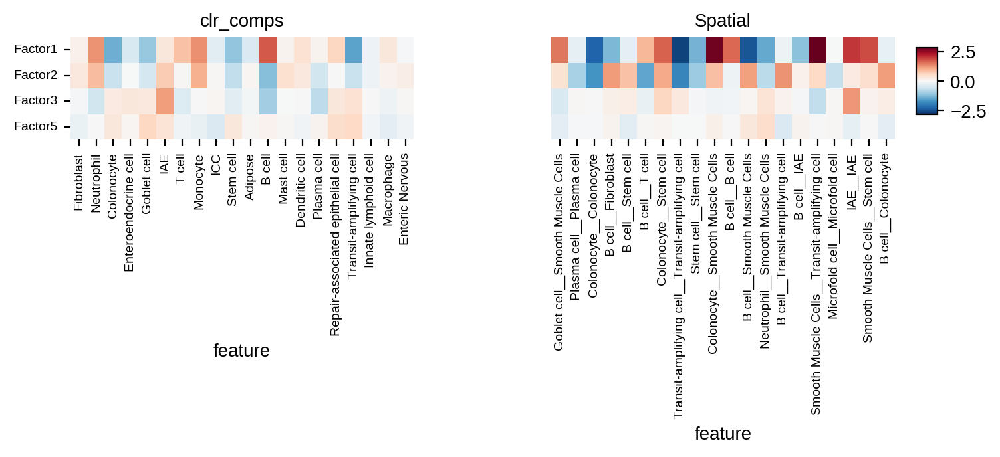

In [27]:
from unittest.mock import patch
import matplotlib.pyplot as plt

with patch.object(plt, "show"):
    mca.pl.plot_features_per_view(
        df_dict=loadings_struct,
        features=top_features_space,
        cmap="RdBu_r",
        center=0,
        share_color_scale=True,
        figsize=(8, 1)
    )

    fig = plt.gcf()

fig.savefig(
    "./results/Figures/Figure3/structural_loadings_inflammation.pdf",
    bbox_inches="tight"
)

plt.show()

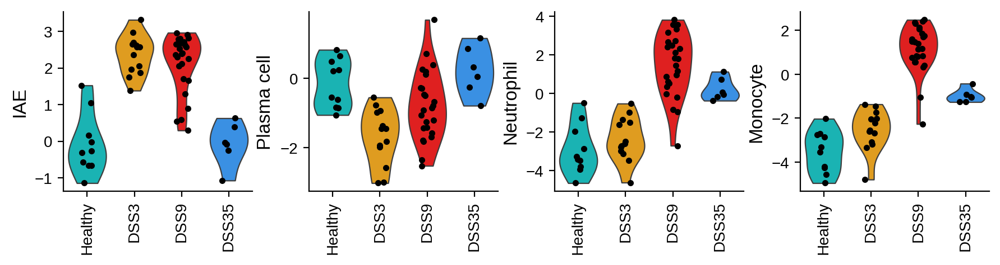

In [28]:
sc.pl.violin(anndata_dict_cleaned["clr_comps"],
             ["IAE", "Plasma cell", "Neutrophil", "Monocyte"], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
            palette=custom_palette_dict,
        )

fig = plt.gcf()
fig.set_size_inches(10, 2.2)

for ax in fig.axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=10)  # tick labels
    ax.xaxis.label.set_size(12)                # x-axis label
    ax.yaxis.label.set_size(12)                # y-axis label

    ax.tick_params(axis="x", pad=3)
    #ax.yaxis.set_label_coords(-0.19, 0.5)

#fig.tight_layout(w_pad=5)
# Then explicitly increase horizontal gap between panels
fig.subplots_adjust(wspace=0.45)
plt.savefig("./results/Figures/Figure3/violin_cts_comps.pdf",
            bbox_inches="tight",
            pad_inches=0.08)
plt.show()
plt.close(fig)  # Explicitly finish this figure

In [29]:
gene_loadings = {
    i: loadings[i]
    for i in loadings.keys()
    if i not in ["clr_comps", "Spatial"]
}

progeny_full = dc.op.progeny(organism="mouse", top=500)

paths = ["NFkB", "JAK-STAT", "TNFa"]
progeny_full = progeny_full[progeny_full["source"].isin(paths)]

# Now you can run decoupler for each matrix of gene loadings
mcp_pws = mca.down.run_ulm_per_view(view_dict=gene_loadings, net= progeny_full)

Running ULM for view: Endothelial
Running ULM for view: EntericNervous
Running ULM for view: Epithelial
Running ULM for view: Fibroblast
Running ULM for view: Immune
Running ULM for view: Smooth Muscle Cells


/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/seaborn/utils.py:61: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:517: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
/tmp/ipykernel_2122907/3779289076.py:14: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK ST

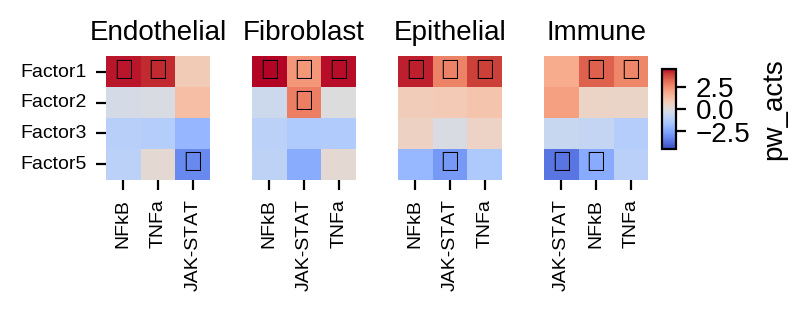

In [31]:
cts_to_plot = ["Endothelial", "Fibroblast", "Epithelial", "Immune"]
mcp_pws = {ct: mcp_pws[ct] for ct in cts_to_plot if ct in mcp_pws.keys()}

with patch.object(plt, "show"):
    mca.pl.plot_mcell_funcomics(mcp_pws, 
                     p_threshold=0.05,
                     top_n=15,
                     use_var=True,
                     figsize=(3.5, 0.8), 
                     center = 0)

    fig = plt.gcf()

fig.savefig(
    "./results/Figures/Figure3/progeny_inflammation.pdf",
    bbox_inches="tight"
)

plt.show()



/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


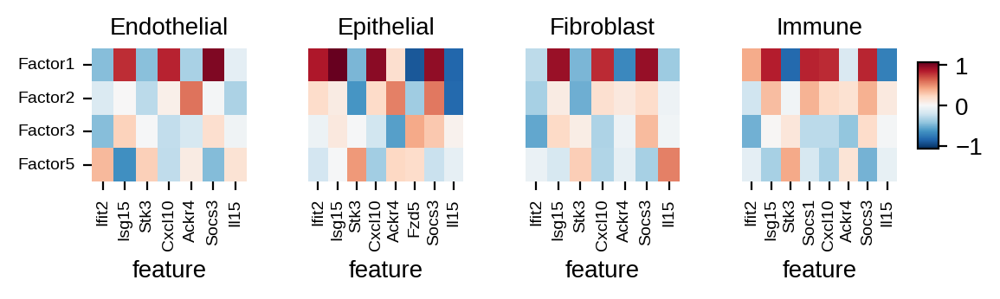

In [32]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor1"]
plt_views = ["Endothelial", "Fibroblast", "Epithelial", "Immune"]
jak_stat_genes = progeny_full[progeny_full["source"] == "JAK-STAT"]["target"].to_list()
n = 2

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                sel_feats = [gene for gene in df.columns.values.tolist() if gene in jak_stat_genes]
                df = df[sel_feats]
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
                top_features.extend(bottomn)
            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(6, 1))


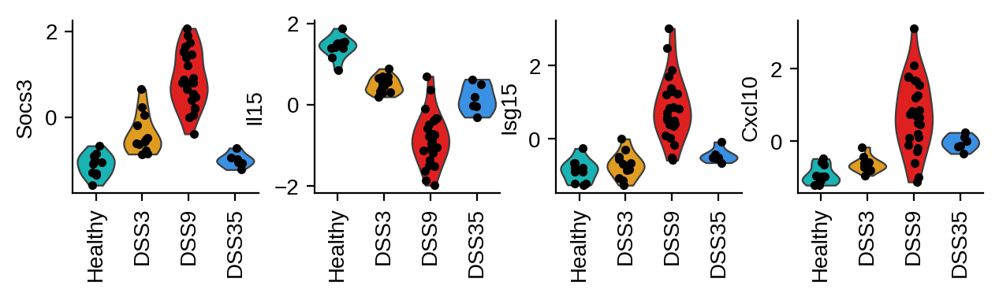

In [33]:
sc.pl.violin(anndata_dict_cleaned["Epithelial"],
             ["Socs3", "Il15", "Isg15", "Cxcl10"], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
            palette=custom_palette
        )

fig = plt.gcf()
fig.set_size_inches(7, 1.5)

for ax in fig.axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)


plt.savefig("./results/Figures/Figure3/epithelial_mainfactors_gex.pdf",
            bbox_inches="tight",
            pad_inches=0.08)
plt.show()
plt.close(fig)  # Explicitly finish this figure

### Factor 3 stress characteristics

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


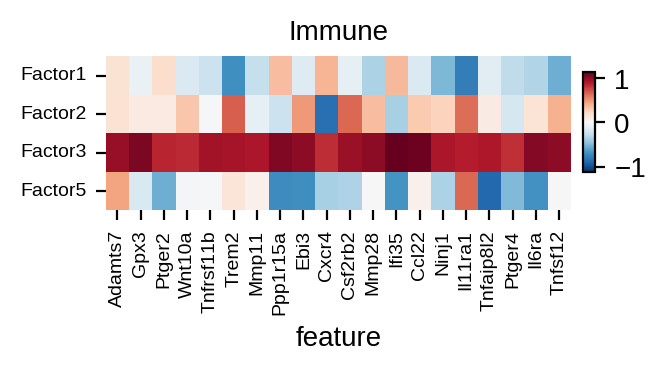

In [34]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor3"]
plt_views = ["Immune"]
n = 20

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(3, 1))

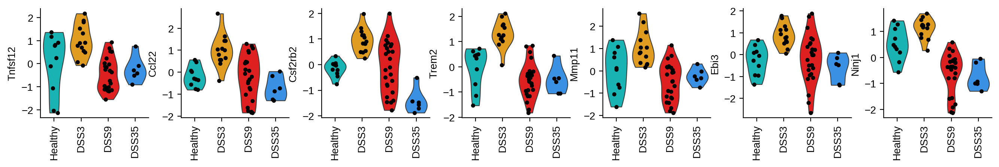

In [36]:
sc.pl.violin(anndata_dict_cleaned["Immune"],
             ['Tnfsf12', 'Ccl22', 'Csf2rb2', 'Trem2', 'Mmp11', 'Ebi3', 'Ninj1'], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
            palette=custom_palette
        )

fig = plt.gcf()
fig.set_size_inches(15, 2)

for ax in fig.axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)

#fig.tight_layout(w_pad=3)
plt.show()
plt.close(fig)  # Explicitly finish this figure

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


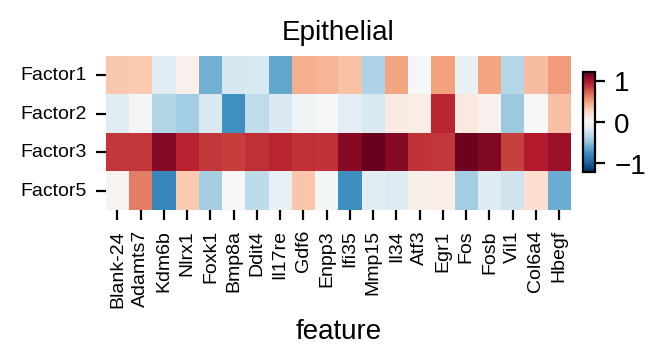

In [37]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor3"]
plt_views = ["Epithelial"]
n = 20

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(3, 1))

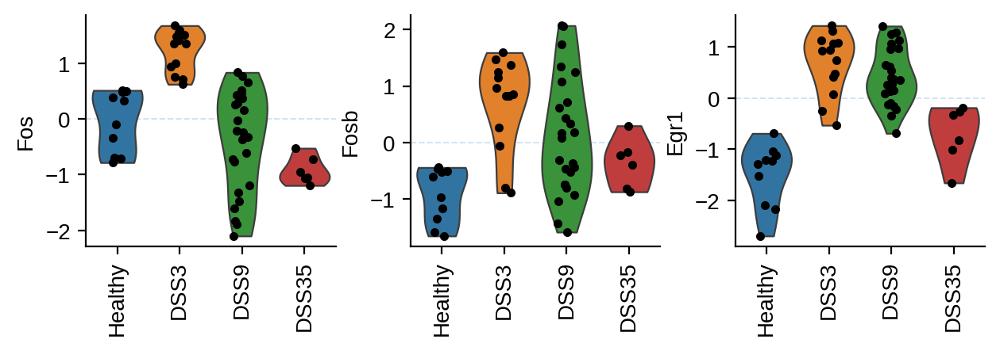

In [38]:
sc.pl.violin(anndata_dict_cleaned["Epithelial"],
             ['Fos','Fosb', 'Egr1'], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
        )

fig = plt.gcf()
fig.set_size_inches(7, 2)

for ax in fig.axes:
    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.7,
        alpha=0.2,
        zorder=0,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)

#fig.tight_layout(w_pad=3)
plt.show()
plt.close(fig)  # Explicitly finish this figure

### Comparison of MINs (Early and peak inflammation)

In [41]:
loadings_red = {view: df for view, df in loadings.items() if view not in ["Spatial","clr_comps"]}

MINs_F1 = mca.down.get_multicell_net(
    test_model = amodel_full,
    sel_factor = "Factor1",
    random_effect = None,
    standardize = True,
    drop_na = True,
    verbose = True,
    views=[k for k in loadings_red.keys()],
    percentile=0.8
)

MINs_F3 = mca.down.get_multicell_net(
    test_model = amodel_full,
    sel_factor = "Factor3",
    random_effect = None,
    standardize = True,
    drop_na = True,
    verbose = True,
    views=[k for k in loadings_red.keys()],
    percentile=0.8
)

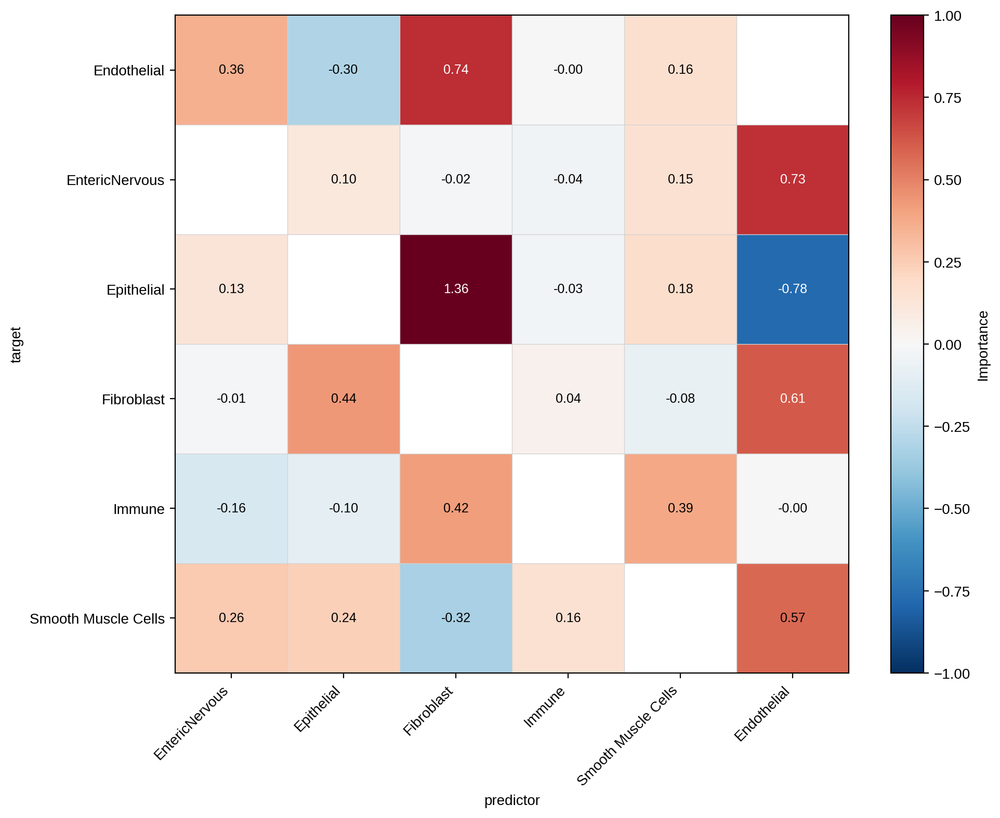

In [42]:
mca.pl.plot_interaction_tileplot(df=MINs_F1["positive"], 
                          value_col="cor_estimate", 
                          row_col="target", col_col="predictor", 
                          cluster_by = None, same_order_for_rows_cols=True, 
                          fill_missing_for_clustering=0.0, 
                          cmap="RdBu_r", center=0.0, vlim=1, 
                          show_values=True, value_decimals=2, 
                          figsize=(10, 8), cbar_label="Importance", linewidth=0.5, linecolor="lightgrey", text_kwargs=None)

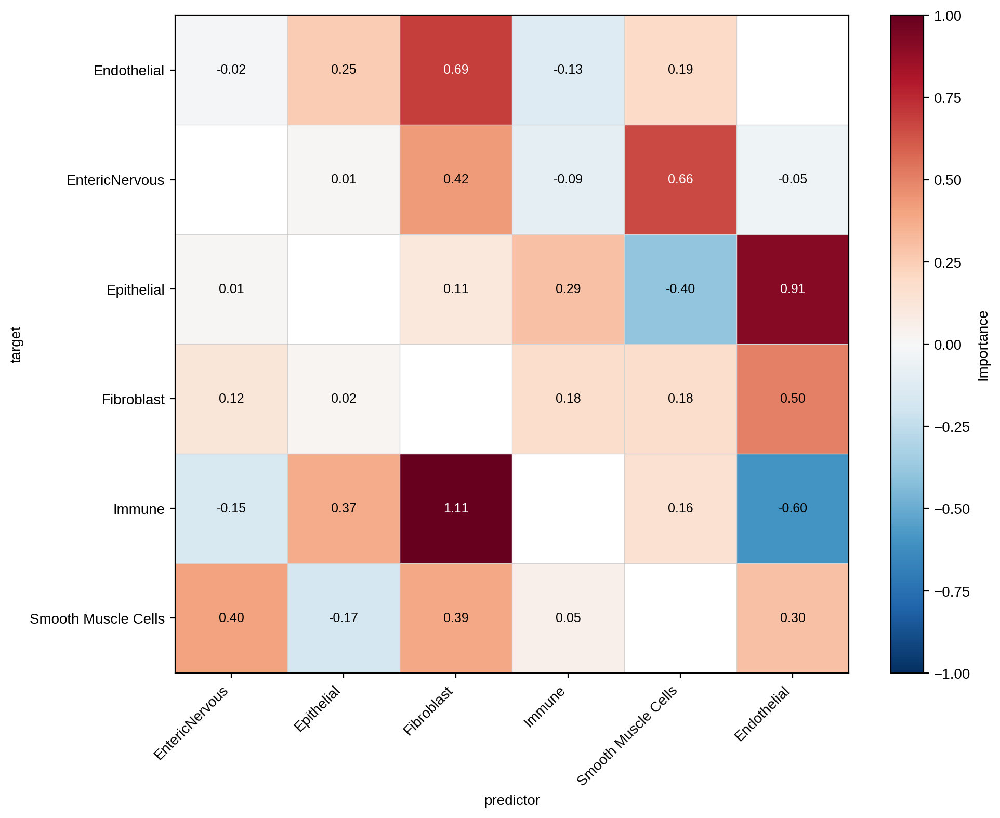

In [43]:
mca.pl.plot_interaction_tileplot(df=MINs_F3["positive"], 
                          value_col="cor_estimate", 
                          row_col="target", col_col="predictor", 
                          cluster_by = None, same_order_for_rows_cols=True, 
                          fill_missing_for_clustering=0.0, 
                          cmap="RdBu_r", center=0.0, vlim=1, 
                          show_values=True, value_decimals=2, 
                          figsize=(10, 8), cbar_label="Importance", linewidth=0.5, linecolor="lightgrey", text_kwargs=None)

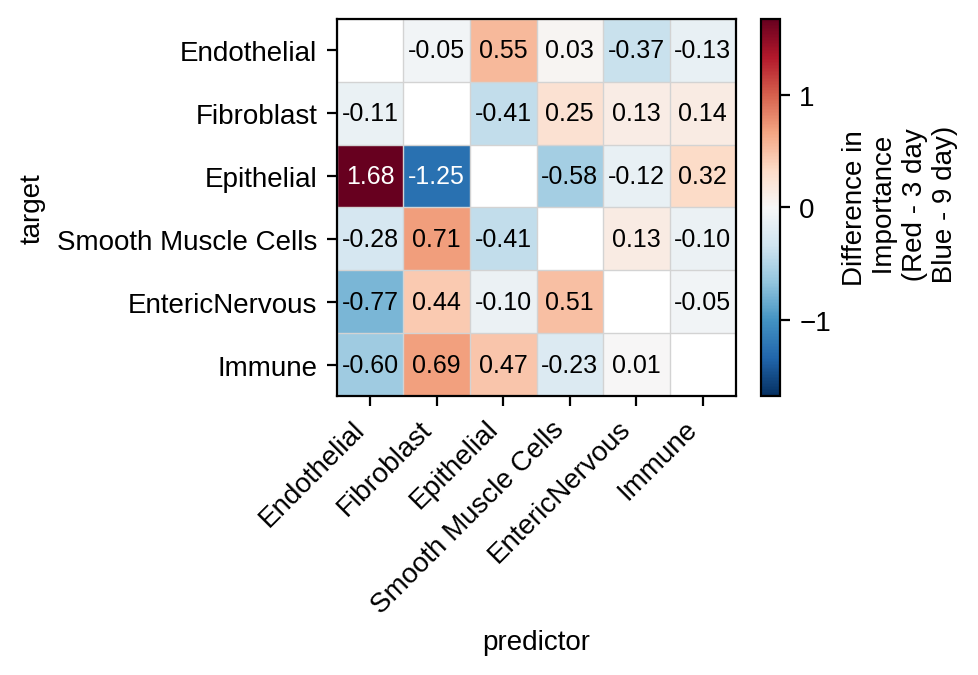

In [44]:
# Make the change between the two dataframes and plot the difference
MINs_F3["change"] = MINs_F3["positive"].copy()
# Ensure that the target and predictor columns are the same in both dataframes
MINs_F3["change"] = MINs_F3["change"].merge(MINs_F1["positive"], on=["target", "predictor"], suffixes=("_early", "_late"))
MINs_F3["change"]["cor_estimate"] = MINs_F3["change"]["cor_estimate_early"] - MINs_F3["change"]["cor_estimate_late"]

mca.pl.plot_interaction_tileplot(df=MINs_F3["change"], value_col="cor_estimate", row_col="target", col_col="predictor", 
                          cluster_by = "columns", same_order_for_rows_cols=True, 
                          fill_missing_for_clustering=0.0, 
                          cmap="RdBu_r", center=0.0, vlim=None, 
                          show_values=True, value_decimals=2, 
                          figsize=(5, 3.5), cbar_label="Difference in\n Importance\n (Red - 3 day\n Blue - 9 day)", 
                          linewidth=0.5, linecolor="lightgrey", text_kwargs=None)

## Doing LIANA++ analyses

In [46]:
import liana as li

resource = li.rs.select_resource('consensus',)

map_df = li.rs.get_hcop_orthologs(columns=['human_symbol', 'mouse_symbol'],
                                  min_evidence=3
                                  ).rename(columns={'human_symbol':'source',
                                                   'mouse_symbol':'target'})

m_resource = li.rs.translate_column(resource=resource,
                                   map_df=map_df,
                                   column='ligand',
                                   one_to_many=1)

m_resource = li.rs.translate_column(resource=m_resource,
                                   map_df=map_df,
                                   column='receptor',
                                   one_to_many=1)

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/resource/_orthology.py:228: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.


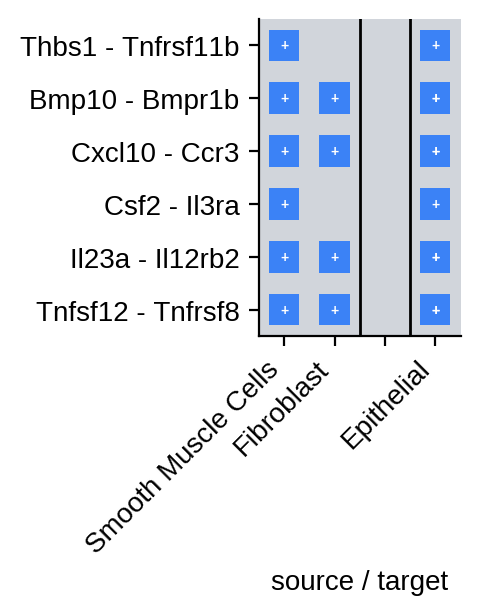

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.


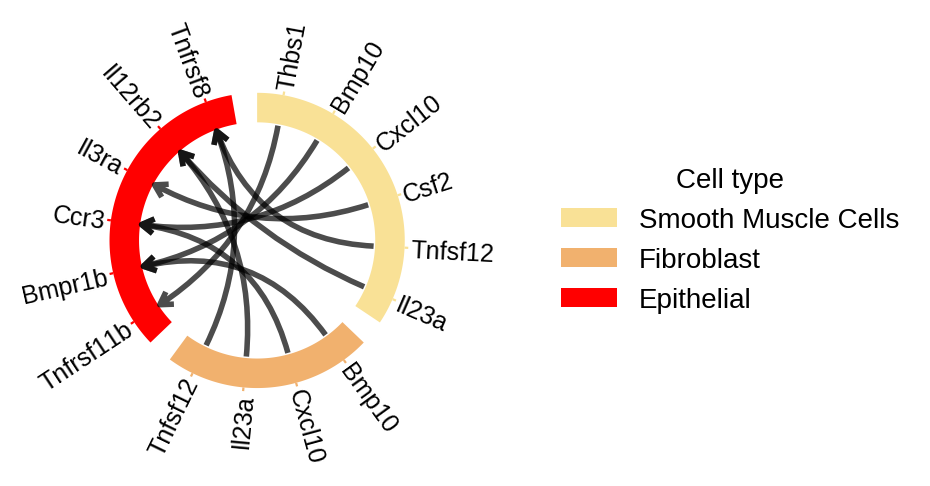

In [48]:
comm_summary = mca.down.lr_usage(
    gene_loadings=loadings_red,
    resource=m_resource,
    network_df=MINs_F1["positive"].copy(),
    sel_factor="Factor1",
    weight_col="cor_estimate",
    abs_cutoff=0.1,
    keep_negative=True,
    loading_type="positive",
    n_top=None,
)

comm_summary = comm_summary[comm_summary["target"].isin(["Epithelial"])]
comm_summary = comm_summary[comm_summary["source"].isin(["Fibroblast","Smooth Muscle Cells"])]
comm_summary = comm_summary.head(10)

fig, ax = mca.pl.plot_comm_overview(
    plot_df = comm_summary,
    tile_width=0.6,
    tile_height=0.6,
    text_size=5,
    figsize=(2.5
    , 3.2),
)
plt.show()

fig, ax = mca.pl.plot_lr_circos(
    plot_df =  comm_summary,
    sector_colors = {
        "Epithelial": "red",
        "Fibroblast": "#F1B16E",
        "Smooth Muscle Cells": "#F9E196",
    },
    link_width = 2,
    arrow_height = 8,
    arrow_width = 8,
    gene_label_size = 9,
    sector_gap = 10,
    figsize=(2, 3),
    legend_kwargs={
        "loc": "center left",
        "bbox_to_anchor": (1.4, 0.5),
        "frameon": False,
        "title": "Cell type",
    },
    sector_r_lim = (80, 100),

)


gene_list = comm_summary["ligand"].tolist() + comm_summary["receptor"].tolist()
gene_list = list(set(gene_list))

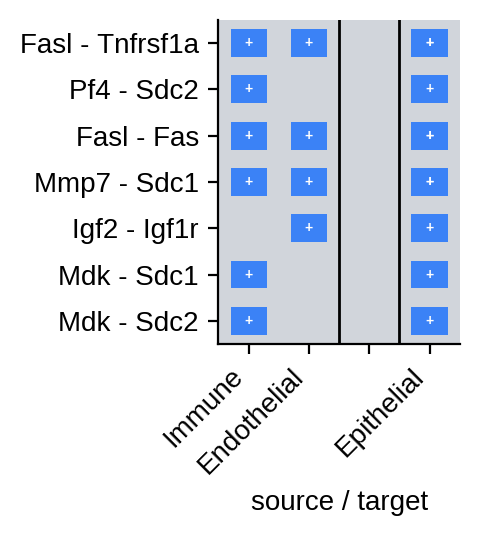

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.


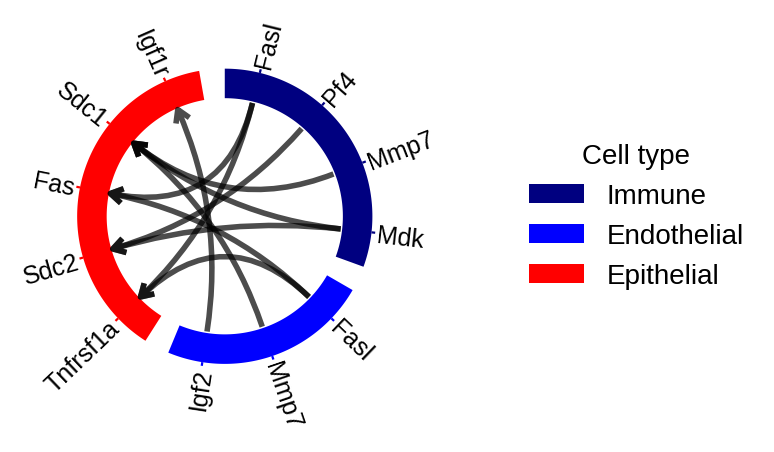

In [ ]:
comm_summary_early = mca.down.lr_usage(
    gene_loadings=loadings_red,
    resource=m_resource,
    network_df=MINs_F3["positive"].copy(),
    sel_factor="Factor3",
    weight_col="cor_estimate",
    abs_cutoff=0.1,
    keep_negative=True,
    loading_type="positive",
    n_top=None,
)

comm_summary_early = comm_summary_early[comm_summary_early["target"].isin(["Epithelial"])]
comm_summary_early = comm_summary_early[comm_summary_early["source"].isin(["Endothelial","Immune"])]
comm_summary_early = comm_summary_early.head(10)

fig, ax = mca.pl.plot_comm_overview(
    plot_df = comm_summary_early,
    tile_width=0.6,
    tile_height=0.6,
    text_size=5,
    figsize=(2.5, 2.8),
)
plt.show()


fig, ax = mca.pl.plot_lr_circos(
    plot_df =  comm_summary_early,
    sector_colors = {
        "Epithelial": "red",
        "Immune": "navy",
        "Endothelial": "blue",
    },
    link_width = 2,
    arrow_height = 8,
    arrow_width = 8,
    gene_label_size = 9,
    sector_gap = 10,
    figsize=(2, 3),
    legend_kwargs={
        "loc": "center left",
        "bbox_to_anchor": (1.4, 0.5),
        "frameon": False,
        "title": "Cell type",
    },
    sector_r_lim = (80, 100),

)

gene_list = gene_list + comm_summary_early["ligand"].tolist() + comm_summary_early["receptor"].tolist()
gene_list = list(set(gene_list))

In [51]:
comm_summary_early["receptor"].unique().tolist()

['Tnfrsf1a', 'Sdc2', 'Fas', 'Sdc1', 'Igf1r']

In [52]:
comm_summary["receptor"].unique().tolist()

['Tnfrsf11b', 'Bmpr1b', 'Ccr3', 'Il3ra', 'Il12rb2', 'Tnfrsf8']

In [54]:
amodel_full.obs["Factor1"] = amodel_full.X[:,0].copy()
amodel_full.obs["Factor3"] = amodel_full.X[:,2].copy()

late_slides = amodel_full.obs.sort_values(by = "Factor1", ascending =  False).head(4).index.to_list()
early_slides = amodel_full.obs.sort_values(by = "Factor3", ascending =  False).head(4).index.to_list()

### Inflow

In [98]:
inflow_res = {}
slides = late_slides + early_slides

for ix in [0,1,2,3,4,5,6,7]:
    slide = slides[ix]
    adata_temp = adata[adata.obs["Slice_ID"] == slide,].copy()
    sc.pp.normalize_total(adata_temp, target_sum=1e4)
    sc.pp.log1p(adata_temp)
    fos_gex = adata_temp[:, "Fos"].X.copy()
    adata_temp = adata_temp[:, gene_list]
    li.ut.spatial_neighbors(adata=adata_temp, bandwidth=50, spatial_key="spatial")
    li.pl.connectivity(adata_temp, idx=5500, size=0.01, figure_size=(6, 5), spatial_key="spatial")
    sq.gr.spatial_autocorr(adata_temp, mode='moran', use_raw=False, show_progress_bar=True)

    lrdata = li.mt.inflow(adata_temp,
                      groupby='Tier1',
                      resource=m_resource,
                      use_raw=False)

    lrdata.obs["Fos"] = fos_gex
    
    inflow_res[slide] = lrdata.copy()

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/utils/spatial_neighbors.py:173: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/method/sp/_inflow.py:316: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/utils/spatial_neighbors.py:173: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/method/sp/_inflow.py:316: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/liana/utils/spatial_neighbors.py:173: Implic

In [99]:
#Define variables
cell_type_col = "Tier1"
spatial_key = "spatial"
interaction = ['Endothelial^Fasl^Tnfrsf1a', 'Smooth Muscle Cells^Bmp10^Bmpr1b']
interaction = ['Endothelial^Mmp7^Sdc1', 'Fibroblast^Il23a^Il12rb2']

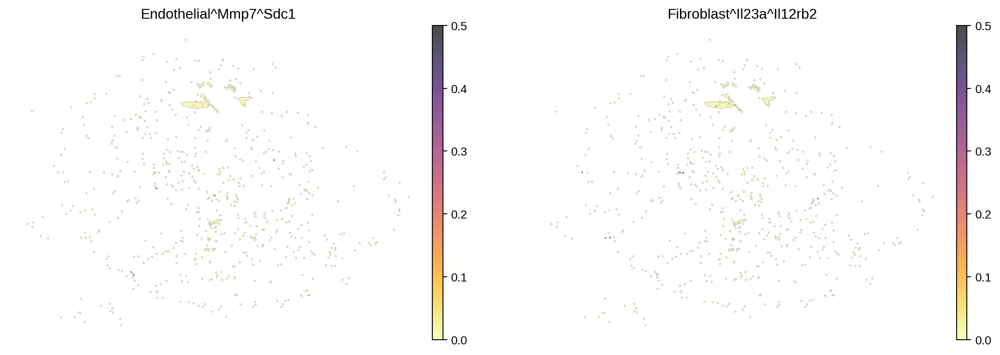

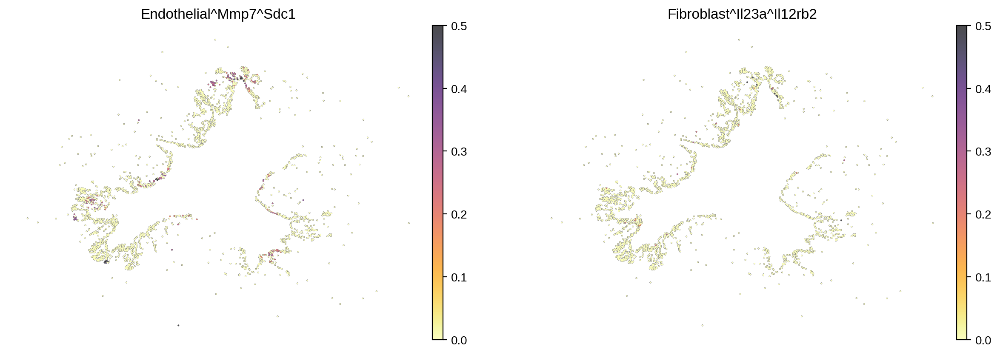

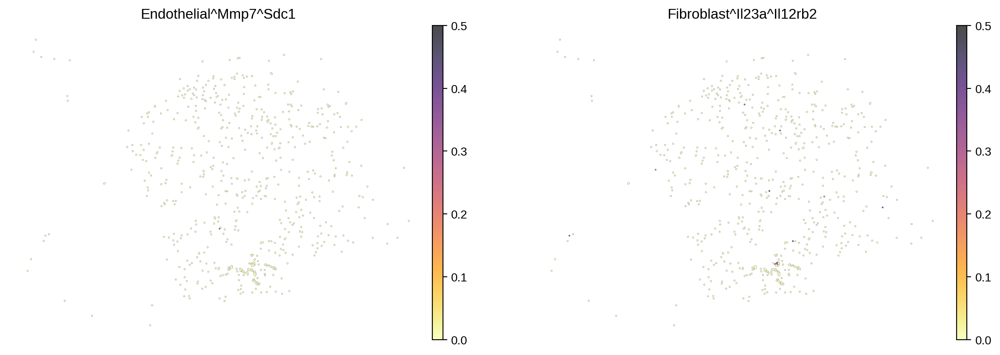

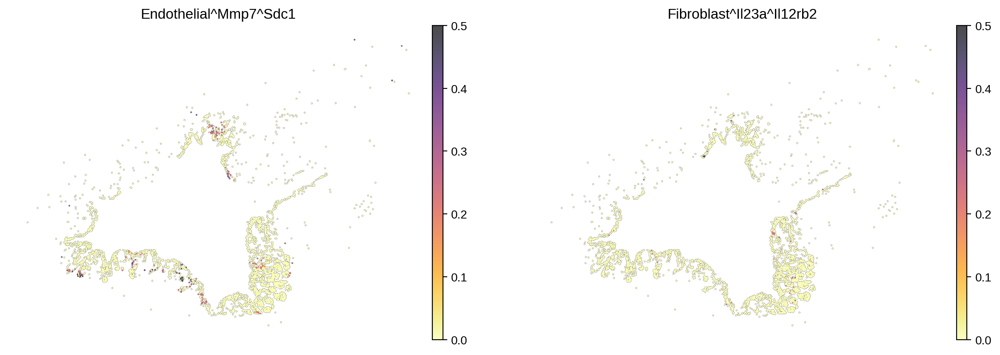

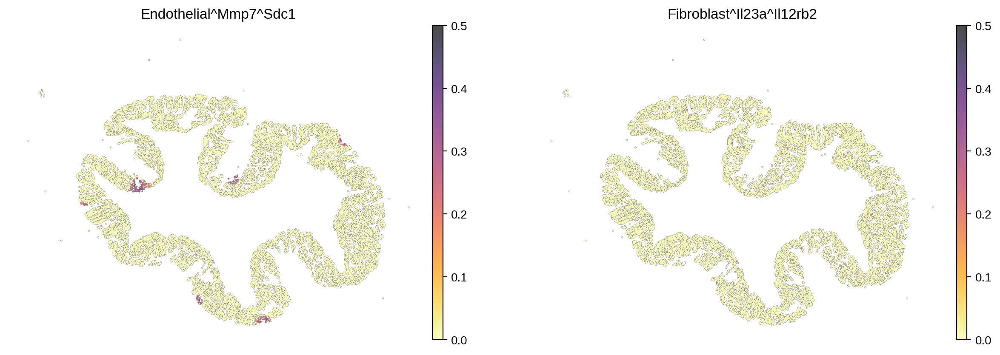

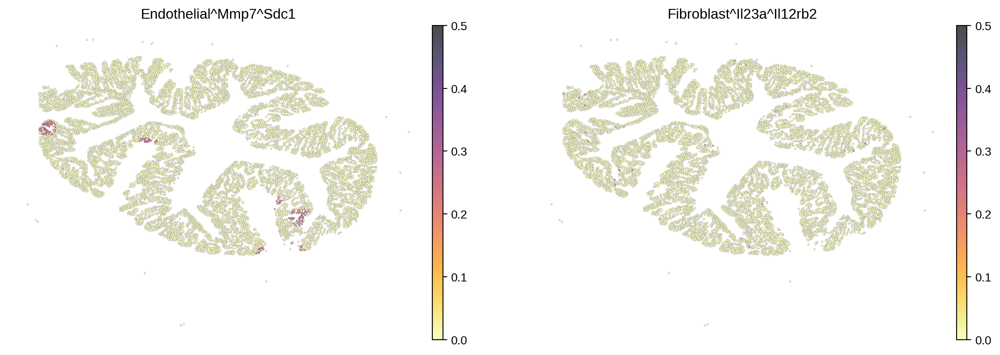

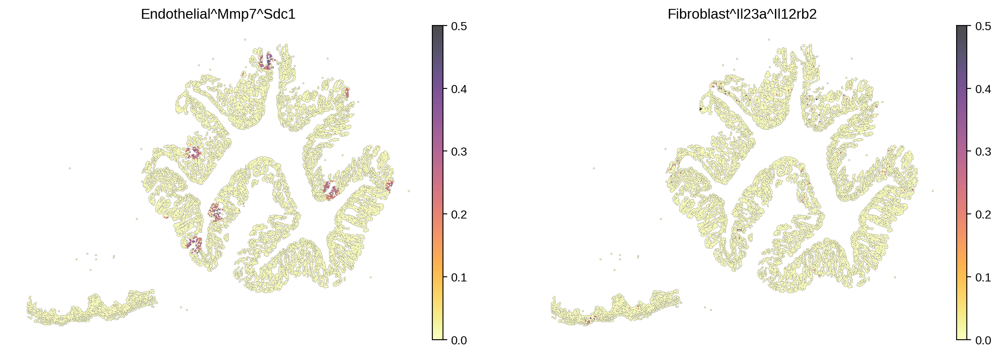

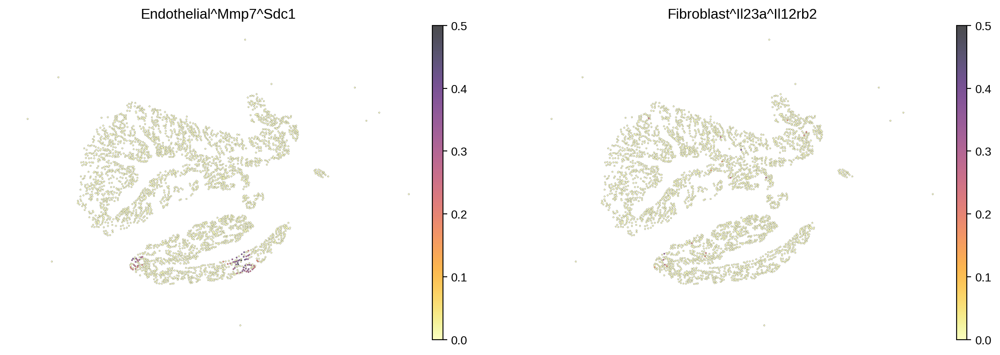

In [102]:
from matplotlib.colors import Normalize

for ind_iflow in list(inflow_res.keys()):

    adata_temp = inflow_res[ind_iflow]

    shared_norm = Normalize(
        vmin=0,
        vmax=1,
        clip=False
    )

    sc.pl.embedding(
        adata_temp[adata_temp.obs["Tier1"].isin(["Epithelial"]), :],
        basis=spatial_key,
        color=interaction,
        s=5,
        ncols=2,
        cmap='inferno_r',
        frameon=False,
        #norm = shared_norm,
        add_outline = True,
        outline_width = (0.1, 0.02),
        vmax = 0.5
    )

### Cumulative damage

In [106]:
amodel_full.var.loc["Factor5"] 

Endothelial:group_1            0.074037
EntericNervous:group_1         0.063320
Epithelial:group_1             0.084214
Fibroblast:group_1             0.093353
Immune:group_1                 0.089638
Smooth Muscle Cells:group_1    0.084242
clr_comps:group_1              0.019803
spatial:group_1                0.021235
Name: Factor5, dtype: float64

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


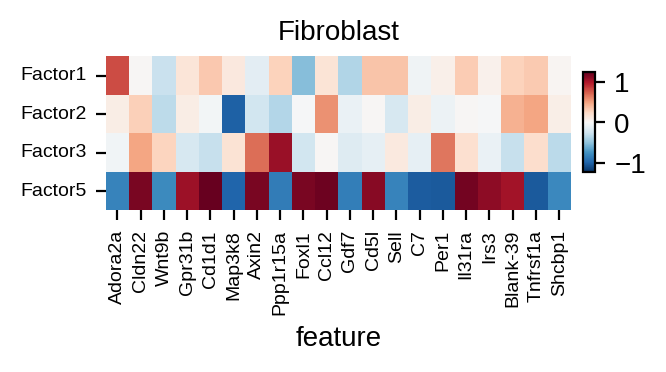

['Adora2a', 'Cldn22', 'Wnt9b', 'Gpr31b', 'Cd1d1', 'Map3k8', 'Axin2', 'Ppp1r15a', 'Foxl1', 'Ccl12', 'Gdf7', 'Cd5l', 'Sell', 'C7', 'Per1', 'Il31ra', 'Irs3', 'Blank-39', 'Tnfrsf1a', 'Shcbp1']


In [127]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor5"]
plt_views = ["Fibroblast"]
n = 10

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
                top_features.extend(bottomn)

            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(3, 1))

print(top_features)

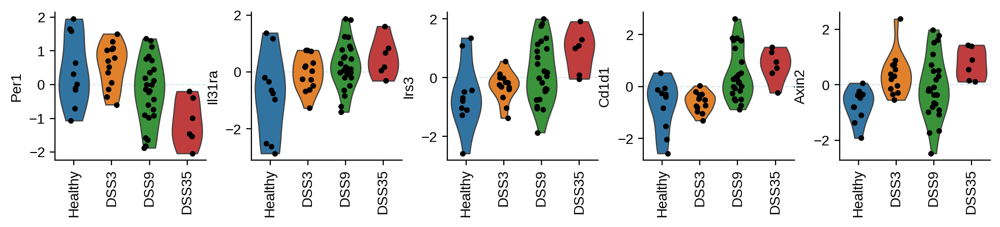

In [128]:
sc.pl.violin(anndata_dict_cleaned["Fibroblast"],
            ['Per1', 'Il31ra', 'Irs3', 'Cd1d1', 'Axin2'], 
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
        )

fig = plt.gcf()
fig.set_size_inches(11, 2)

for ax in fig.axes:
    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.7,
        alpha=0.2,
        zorder=0,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)

#fig.tight_layout(w_pad=3)
plt.show()
plt.close(fig)  # Explicitly finish this figure

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


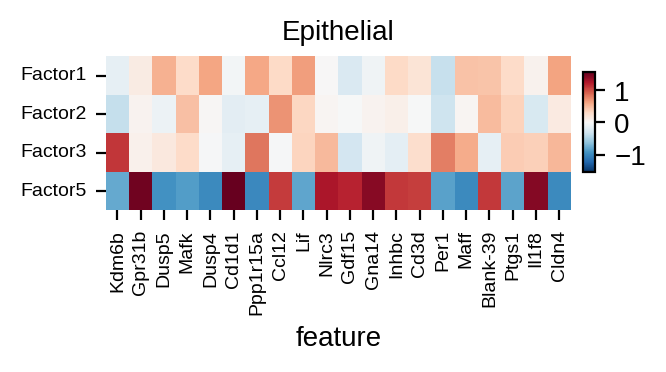

In [129]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor5"]
plt_views = ["Epithelial"]
n = 10

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
                top_features.extend(bottomn)

            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(3, 1))

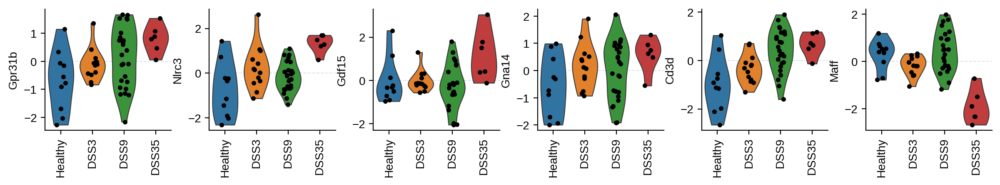

In [130]:
sc.pl.violin(anndata_dict_cleaned["Epithelial"],
            np.array(top_features)[[1,9,10,11,13,15]],
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
        )

fig = plt.gcf()
fig.set_size_inches(13.5, 2)

for ax in fig.axes:
    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.7,
        alpha=0.2,
        zorder=0,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)

#fig.tight_layout(w_pad=3)
plt.show()
plt.close(fig)  # Explicitly finish this figure

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/pl/pl.py:1062: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


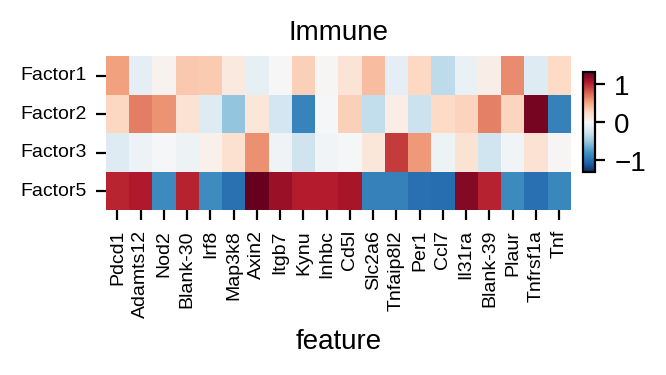

In [131]:
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
# Get top 5 and bottom 5 loadings per factor and view of a given factor from loadings
factors = ["Factor5"]
plt_views = ["Immune"]
n = 10

top_features = []

for view, df in loadings.items():
    if view in plt_views:
        for factor in factors:
            if factor in factors:
                topn = df.loc[factor].nlargest(n).index.to_list()
                bottomn = df.loc[factor].nsmallest(n).index.to_list()
                top_features.extend(topn)
                top_features.extend(bottomn)

            else: 
                continue

top_features = list(set(top_features))  # Remove duplicates

loadings_red = {view: df for view, df in loadings.items() if view in plt_views}

# Keep only genes present in pathway_membership index
mca.pl.plot_features_per_view(df_dict=loadings_red, 
                               features=top_features, 
                               cmap="RdBu_r",
                               center=0,
                               share_color_scale=True,
                               figsize=(3, 1))

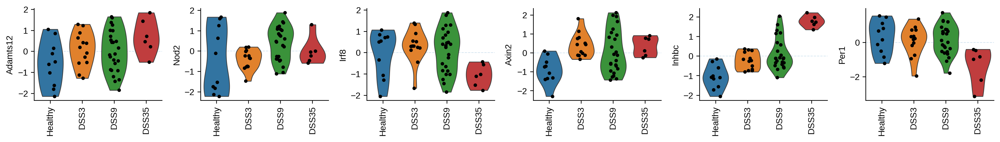

In [132]:
sc.pl.violin(anndata_dict_cleaned["Immune"],
            np.array(top_features)[[1,2,4,6,9,13]],
             groupby="Sample_type",
             jitter=0.15,
            stripplot=True,
            rotation=90,
            dodge=False,
            size=4,
            linewidth=0.8,
            inner=None,
            cut=0,
            show=False,
        )

fig = plt.gcf()
fig.set_size_inches(18, 2)

for ax in fig.axes:
    ax.axhline(
        0,
        linestyle="--",
        linewidth=0.7,
        alpha=0.2,
        zorder=0,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(axis="x", pad=3)

#fig.tight_layout(w_pad=3)
plt.show()
plt.close(fig)  # Explicitly finish this figure